# Task 7 (Day 7): Explain every flag with reason codes and money at risk
**Objective.** Give each flag a reason code, a plain sentence and an estimate of the money at risk, in the official output format.
**Why it matters.** Unexplained alerts get ignored. A clear reason and a rupee amount makes people act.
**You will learn.** Designing a useful output, mapping model signals to reasons, estimating money at risk, matching an output format, prioritising alerts.
**Rule.** Same 12 columns as `sample_anomaly_results`, in the same order. Reasons are written first, models second: "the model said so" is not a reason.

In [1]:
import sys, pathlib, json, re, warnings
warnings.filterwarnings('ignore')
ROOT = pathlib.Path.cwd().resolve()
while not (ROOT / 'src').exists(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src')); sys.path.insert(0, str(ROOT / '05_Starter')); sys.path.insert(0, str(ROOT / 'scripts'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 60); pd.set_option('display.max_colwidth', 120)
from cortexhr import config as C
from cortexhr.phase2 import payroll as P, chatbot as CB, service as S
import cortexhr_helpers as H; H.DATA = ROOT / '03_Data' / 'csv'      # the OFFICIAL starter helper (unmodified)
CSV = ROOT / '03_Data' / 'csv'; OUT = ROOT / 'reports' / 'phase2'; MOCK = ROOT / '05_Starter' / 'mock_services' / 'mock_data'
print('Python', sys.version.split()[0], '| project root:', ROOT)

Python 3.12.3 | project root: /home/claude/cortexhr_phase1-main


---
# Stage 1 of 12: Data Collection
The official sample sheet and our frozen payroll predictions from Task 6.

In [2]:
sample = H.load('sample_anomaly_results'); frozen = pd.read_csv(OUT / 'payroll_predictions_frozen.csv', parse_dates=['month'])
print('sample sheet:', sample.shape, '| ours (frozen, all rows scored):', frozen.shape, '| flagged:', int(frozen.flagged.sum()))
sample.head(3)

sample sheet: (405, 12) | ours (frozen, all rows scored): (7355, 30) | flagged: 301


  result_id               source_dataset record_id employee_id      period  anomaly_score flagged    reason_code                               reason_text  money_at_risk           model_version  \
0   AN-0001  attendance_monthly_features  AF-03170    EMP-0356  2025-07-01          1.000       Y  NO_ATTENDANCE  No presence recorded for the whole month            NaN  iforest-attendance-0.1   
1   AN-0002  attendance_monthly_features  AF-05918    EMP-0585  2025-09-01          0.998       Y  NO_ATTENDANCE  No presence recorded for the whole month            NaN  iforest-attendance-0.1   
2   AN-0003  attendance_monthly_features  AF-06802    EMP-0646  2026-06-01          0.998       Y  NO_ATTENDANCE  No presence recorded for the whole month            NaN  iforest-attendance-0.1   

             scored_at  
0  2026-10-01 02:00:00  
1  2026-10-01 02:00:00  
2  2026-10-01 02:00:00  

---
# Stage 2 of 12: Data Understanding
Study the sample sheet's columns before writing any code.

In [3]:
pd.DataFrame({'dtype': sample.dtypes.astype(str), 'example': sample.iloc[0], 'non-null': sample.notna().sum()})

                  dtype                                   example  non-null
result_id           str                                   AN-0001       405
source_dataset      str               attendance_monthly_features       405
record_id           str                                  AF-03170       405
employee_id         str                                  EMP-0356       405
period              str                                2025-07-01       405
anomaly_score   float64                                       1.0       405
flagged             str                                         Y       405
reason_code         str                             NO_ATTENDANCE       405
reason_text         str  No presence recorded for the whole month       405
money_at_risk   float64                                       NaN       184
model_version       str                    iforest-attendance-0.1       405
scored_at           str                       2026-10-01 02:00:00       405

In [4]:
sample[sample.source_dataset == 'payroll_monthly_features'].sample(5, random_state=1)[['record_id', 'period', 'anomaly_score', 'flagged', 'reason_code', 'reason_text', 'money_at_risk']]

     record_id      period  anomaly_score flagged           reason_code                                                  reason_text  money_at_risk
237  PI-005825  2026-06-01          0.891       Y   STATISTICAL_OUTLIER  Unusual combination of pay ratios versus all other payslips      296590.62
366  PI-001610  2025-08-01          0.664       Y   STATISTICAL_OUTLIER  Unusual combination of pay ratios versus all other payslips           0.00
316  PI-000017  2025-04-01          0.743       Y   STATISTICAL_OUTLIER  Unusual combination of pay ratios versus all other payslips      158208.56
379  PI-007129  2026-09-01          0.646       Y  GROSS_BELOW_EXPECTED      Gross is well below fixed pay with no leave without pay      284135.07
268  PI-005484  2026-05-01          0.813       Y      GROSS_ABOVE_NORM                         Gross is 10.5x the monthly fixed pay      271213.79

---
# Stage 3 of 12: Data Quality Audit
Is every flag explained, and is every amount a real number?

In [5]:
fl = frozen[frozen.flagged]
audit = {'flagged rows': len(fl), 'flags without a reason code': int(fl.reason_code.isin(['', 'NOT_FLAGGED']).sum() + fl.reason_code.isna().sum()),
         'flags without reason text': int(fl.reason_text.isna().sum() + (fl.reason_text.str.len() < 20).sum()),
         'money_at_risk missing/inf/negative': int((~np.isfinite(fl.money_at_risk) | (fl.money_at_risk < 0)).sum()),
         'flags with zero money at risk': int((fl.money_at_risk == 0).sum())}
pd.Series(audit, name='count').to_frame()

                                    count
flagged rows                          301
flags without a reason code             0
flags without reason text               0
money_at_risk missing/inf/negative      0
flags with zero money at risk          25

---
# Stage 4 of 12: Exploratory Data Analysis (EDA)
Which reasons dominate, and how big are the amounts?

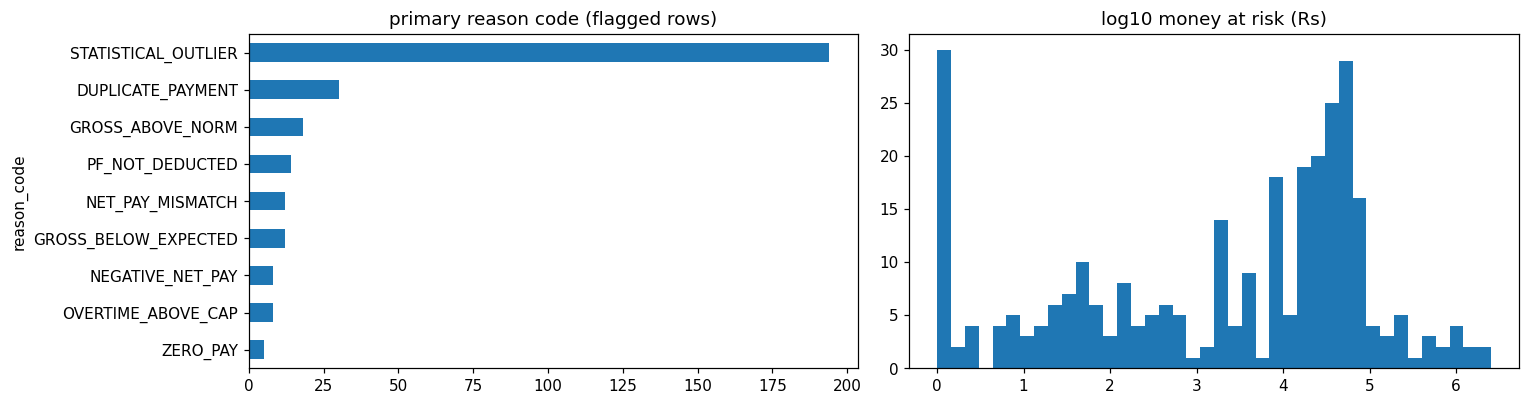

In [6]:
primary = fl.reason_code.str.split('|').str[0]
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
primary.value_counts().plot.barh(ax=ax[0], title='primary reason code (flagged rows)'); ax[0].invert_yaxis()
ax[1].hist(np.log10(fl.money_at_risk.clip(lower=1)), bins=40); ax[1].set_title('log10 money at risk (Rs)')
fig.tight_layout();

---
# Stage 5 of 12: Data Cleaning
Output hygiene: stable types, rounding, no NaN money, ids and periods in the sample's style.

In [7]:
official = P.to_official_format(frozen.assign(month=pd.to_datetime(frozen.month)))
official['money_at_risk'] = official.money_at_risk.round(2)
print('columns equal to sample:', official.columns.tolist() == sample.columns.tolist())
official.head(3)

columns equal to sample: True


  result_id            source_dataset  record_id employee_id      period  anomaly_score flagged                                            reason_code  \
0  P2-00001  payroll_monthly_features  PI-003304    EMP-0304  2025-12-01            0.9       Y  GROSS_ABOVE_NORM|NET_PAY_MISMATCH|STATISTICAL_OUTLIER   
1  P2-00002  payroll_monthly_features  PI-002595    EMP-0453  2025-10-01            0.9       Y  GROSS_ABOVE_NORM|NET_PAY_MISMATCH|STATISTICAL_OUTLIER   
2  P2-00003  payroll_monthly_features  PI-002124    EMP-0331  2025-09-01            0.9       Y  GROSS_ABOVE_NORM|NET_PAY_MISMATCH|STATISTICAL_OUTLIER   

                                                                                                               reason_text  money_at_risk             model_version                         scored_at  
0  Gross pay Rs 2,823,640 is 10.0x the Rs 282,364 that fixed pay, overtime and variable pay explain. Look for an extra ...     2541276.45  payroll-iforest-rules-v2  2026-10-28T08:26:1

---
# Stage 6 of 12: Feature Engineering
The mapping from signals to reasons, and the money-at-risk definition.

In [8]:
pd.DataFrame({'reason_code': list(P.REASON_GLOSSARY), 'plain meaning': list(P.REASON_GLOSSARY.values())})

                 reason_code                                                           plain meaning
0          DUPLICATE_PAYMENT               Two payslips exist for the same employee and payroll run.
1           NEGATIVE_NET_PAY     Net pay is below zero because deductions are larger than gross pay.
2                   ZERO_PAY        Gross or net pay is zero although the employee has payable days.
3           GROSS_ABOVE_NORM  Gross pay is higher than fixed pay, overtime and variable pay explain.
4       GROSS_BELOW_EXPECTED   Gross pay is lower than fixed pay, overtime and variable pay explain.
5           NET_PAY_MISMATCH                Gross minus deductions does not equal the net pay shown.
6   DEDUCTION_TOTAL_MISMATCH      The listed deductions do not add up to the total deductions shown.
7    DEDUCTIONS_EXCEED_GROSS                             Total deductions are larger than gross pay.
8         OVERTIME_ABOVE_CAP                   Paid overtime hours are above the monthly po

**money_at_risk (a ranking estimate, not an audited loss).** Overpayment = paid minus what fixed pay, payable days, overtime and variable pay explain (`expected_gross`); a duplicate payslip counts the net pay paid twice; missing PF counts the PF owed; overtime above the cap counts the extra overtime pay; negative or zero pay counts the amount that should have been paid. Finance validates the final figure.

In [9]:
x = frozen[frozen.flagged].copy(); x['paid_minus_expected_gross'] = (x.gross_pay - x.expected_gross).round(0)
x[x.GROSS_ABOVE_NORM][['payroll_item_id', 'gross_pay', 'expected_gross', 'paid_minus_expected_gross', 'money_at_risk']].head(5)

  payroll_item_id  gross_pay  expected_gross  paid_minus_expected_gross  money_at_risk
0       PI-003304  2823640.5       282364.05                  2541276.0     2541276.45
1       PI-002595  2424310.0       242431.00                  2181879.0     2181879.00
2       PI-002124  1775780.0       177578.00                  1598202.0     1598202.00
3       PI-003441  1654890.0       165489.00                  1489401.0     1489401.00
4       PI-007199  1286250.0       128625.00                  1157625.0     1157625.00

---
# Stage 7 of 12: Train-Test Split
There is no model training in this task, so the held-out piece is the 20-row review sample chosen BEFORE reading any reason text: one pick per reason code first, then the largest remaining amounts.

In [10]:
rs = np.random.RandomState(C.SEED)
fl2 = frozen[frozen.flagged].assign(primary=lambda d: d.reason_code.str.split('|').str[0])
first = fl2.groupby('primary', group_keys=False).apply(lambda g: g.sample(1, random_state=rs)).head(20)
rest = fl2[~fl2.payroll_item_id.isin(first.payroll_item_id)].sort_values('money_at_risk', ascending=False).head(20 - len(first))
review_ids = pd.concat([first, rest]).payroll_item_id.tolist()
print(len(review_ids), 'review rows chosen;', fl2[fl2.payroll_item_id.isin(review_ids)].primary.nunique(), 'different primary reason codes')

20 review rows chosen; 9 different primary reason codes


---
# Stage 8 of 12: Model Building
Put the results into the official format and rank by money at risk.

In [11]:
flagged_out = P.to_official_format(frozen.assign(month=pd.to_datetime(frozen.month)), flagged_only=True)
flagged_out[['result_id', 'record_id', 'employee_id', 'period', 'flagged', 'reason_code', 'money_at_risk']].head(8)

  result_id  record_id employee_id      period flagged                                            reason_code  money_at_risk
0  P2-00001  PI-003304    EMP-0304  2025-12-01       Y  GROSS_ABOVE_NORM|NET_PAY_MISMATCH|STATISTICAL_OUTLIER     2541276.45
1  P2-00002  PI-002595    EMP-0453  2025-10-01       Y  GROSS_ABOVE_NORM|NET_PAY_MISMATCH|STATISTICAL_OUTLIER     2181879.00
2  P2-00003  PI-002124    EMP-0331  2025-09-01       Y  GROSS_ABOVE_NORM|NET_PAY_MISMATCH|STATISTICAL_OUTLIER     1598202.00
3  P2-00004  PI-003441    EMP-0533  2025-12-01       Y  GROSS_ABOVE_NORM|NET_PAY_MISMATCH|STATISTICAL_OUTLIER     1489401.00
4  P2-00005  PI-007199    EMP-0590  2026-09-01       Y  GROSS_ABOVE_NORM|NET_PAY_MISMATCH|STATISTICAL_OUTLIER     1157625.00
5  P2-00006  PI-006419    EMP-0669  2026-07-01       Y  GROSS_ABOVE_NORM|NET_PAY_MISMATCH|STATISTICAL_OUTLIER     1097901.00
6  P2-00007  PI-003796    EMP-0459  2026-01-01       Y  GROSS_ABOVE_NORM|NET_PAY_MISMATCH|STATISTICAL_OUTLIER      953163.00


### Think for yourself: two flags have the same reason. How do you decide which comes first?

In [12]:
same = flagged_out[flagged_out.reason_code.str.startswith('NET_PAY_MISMATCH')].head(6)
same[['result_id', 'reason_code', 'anomaly_score', 'money_at_risk']]

    result_id       reason_code  anomaly_score  money_at_risk
38   P2-00039  NET_PAY_MISMATCH            0.9       68037.67
82   P2-00083  NET_PAY_MISMATCH            0.9       37547.79
114  P2-00115  NET_PAY_MISMATCH            0.9       22317.71
129  P2-00130  NET_PAY_MISMATCH            0.9       16519.94
130  P2-00131  NET_PAY_MISMATCH            0.9       16519.94
148  P2-00149  NET_PAY_MISMATCH            0.9        8400.00

**Answer.** By the rupee amount first, because a clerk who can only open ten items should open the ten that could cost most. When amounts tie, use the higher `anomaly_score`, then the id so the order never changes between runs. A rule-confirmed flag also beats a model-only flag with the same amount because it is quicker to verify.

---
# Stage 9 of 12: Model Evaluation
The 4 acceptance checks of the task, as code.

In [13]:
cols_ok = official.columns.tolist() == sample.columns.tolist()
ranked = flagged_out.money_at_risk.is_monotonic_decreasing
reasons_ok = bool((flagged_out.reason_text.str.len() > 40).all() and (~flagged_out.reason_text.str.contains('model said so', case=False)).all())
numbers_in_text = flagged_out.reason_text.str.contains(r'Rs [\d,]+').mean()
pd.Series({'columns match the sample (same names, same order)': cols_ok, 'flags ranked by money at risk (largest first)': ranked,
           'every flag has a plain reason sentence': reasons_ok, 'share of reason texts quoting the row\'s own rupee figures': round(float(numbers_in_text), 3)}).to_frame('result')

                                                          result
columns match the sample (same names, same order)           True
flags ranked by money at risk (largest first)               True
every flag has a plain reason sentence                      True
share of reason texts quoting the row's own rupee figures  0.784

---
# Stage 10 of 12: Hyperparameter Tuning
No model settings to tune here. The one design choice is how many sentences a reason may contain; check it stays readable.

In [14]:
words = flagged_out.reason_text.str.split().str.len(); sentences = flagged_out.reason_text.str.count(r'\. ') + 1
pd.DataFrame({'words': words.describe().round(1), 'sentences': sentences.describe().round(1)})

       words  sentences
count  301.0      301.0
mean    33.7        2.0
std      8.9        0.6
min     17.0        1.0
25%     26.0        2.0
50%     34.0        2.0
75%     35.0        2.0
max     61.0        4.0

Reasons are capped at three sentences (`_compose_reason(max_sentences=3)`), so a clerk reads one short paragraph, not a report.

---
# Stage 11 of 12: Model Interpretation
Can a clerk understand each of 20 flags without help? Read them like a clerk would.

In [15]:
review = flagged_out[flagged_out.record_id.isin(review_ids)][['result_id', 'record_id', 'reason_code', 'reason_text', 'money_at_risk']].reset_index(drop=True)
review.to_csv(OUT / 'payroll_review_sample_20_notebook.csv', index=False)
review.head(5)

  result_id  record_id                                            reason_code  \
0  P2-00001  PI-003304  GROSS_ABOVE_NORM|NET_PAY_MISMATCH|STATISTICAL_OUTLIER   
1  P2-00002  PI-002595  GROSS_ABOVE_NORM|NET_PAY_MISMATCH|STATISTICAL_OUTLIER   
2  P2-00003  PI-002124  GROSS_ABOVE_NORM|NET_PAY_MISMATCH|STATISTICAL_OUTLIER   
3  P2-00004  PI-003441  GROSS_ABOVE_NORM|NET_PAY_MISMATCH|STATISTICAL_OUTLIER   
4  P2-00005  PI-007199  GROSS_ABOVE_NORM|NET_PAY_MISMATCH|STATISTICAL_OUTLIER   

                                                                                                               reason_text  money_at_risk  
0  Gross pay Rs 2,823,640 is 10.0x the Rs 282,364 that fixed pay, overtime and variable pay explain. Look for an extra ...     2541276.45  
1  Gross pay Rs 2,424,310 is 10.0x the Rs 242,431 that fixed pay, overtime and variable pay explain. Look for an extra ...     2181879.00  
2  Gross pay Rs 1,775,780 is 10.0x the Rs 177,578 that fixed pay, overtime and variable pay e

**Friend test (a human step, cannot be automated).** Show `reports/phase2/payroll_review_sample_20.csv` to a friend who knows nothing about the project. Ask: *what is wrong with this payslip and what would you do?* Write their feedback in your report; fix any sentence they could not follow.

---
# Stage 12 of 12: Final Conclusions and Recommendations

In [16]:
print(f'''OUTPUT: {len(flagged_out)} flagged payslips in the 12 official columns, ranked by money at risk (largest first).
TOP ITEM: {flagged_out.iloc[0].record_id} - {flagged_out.iloc[0].reason_code} - Rs {flagged_out.iloc[0].money_at_risk:,.0f}
TOTAL MONEY AT RISK (ranking estimate, not an audited loss): Rs {flagged_out.money_at_risk.sum():,.0f}
RECOMMENDATION: let finance confirm the money formula per reason code, and keep tie-breaking deterministic so reviewers always see the same order.''')

OUTPUT: 301 flagged payslips in the 12 official columns, ranked by money at risk (largest first).
TOP ITEM: PI-003304 - GROSS_ABOVE_NORM|NET_PAY_MISMATCH|STATISTICAL_OUTLIER - Rs 2,541,276
TOTAL MONEY AT RISK (ranking estimate, not an audited loss): Rs 22,009,880
RECOMMENDATION: let finance confirm the money formula per reason code, and keep tie-breaking deterministic so reviewers always see the same order.


### Completion checklist (checked by code)

In [17]:
checks = {
    "'Columns match the sample sheet'": cols_ok,
    "'Every flag has a reason a clerk understands'": reasons_ok,
    "'Flags are ranked by money at risk'": ranked,
    "'20-row test passes (needs a real person)'": 'MANUAL',
}
status = {k: ('MANUAL' if isinstance(v, str) and v == 'MANUAL' else 'PASS' if bool(v) else 'FAIL') for k, v in checks.items()}
for k, v in status.items(): print(f'[{v}]', k)
assert 'FAIL' not in status.values(), 'a checklist item failed'
print('\nchecklist:', sum(v == 'PASS' for v in status.values()), 'PASS,', sum(v == 'MANUAL' for v in status.values()), 'MANUAL (needs a human or a file only you have)')

[PASS] 'Columns match the sample sheet'
[PASS] 'Every flag has a reason a clerk understands'
[PASS] 'Flags are ranked by money at risk'
[MANUAL] '20-row test passes (needs a real person)'

checklist: 3 PASS, 1 MANUAL (needs a human or a file only you have)


### Evidence for your report
Your output table (20 rows) = `reports/phase2/payroll_review_sample_20.csv`, plus your friend's feedback.
References: [pandas](https://github.com/pandas-dev/pandas) | [scikit-learn](https://github.com/scikit-learn/scikit-learn) | [pytest](https://github.com/pytest-dev/pytest)
**How real companies do it:** a reason that says 'the model said so' is not accepted in audits. Teams write reasons first, models second.
**Connects to the next task:** you have detectors with explanations. Task 8 packages them as a service other systems can call.
**You can now say:** *I turned model signals into explanations people can act on.*